# Brain Stroke Prediction - XGBoost Classifier
Steps: Preprocessing -> Encoding techniques -> SMOTE -> XGBoost -> RandomizedSearchCV -> Cross Validation

## Step 1: Import libraries

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and encoding
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Imbalance handling (SMOTE) and pipeline that supports SMOTE
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# Model
from xgboost import XGBClassifier

# Metrics
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

import warnings
warnings.filterwarnings("ignore")

## Step 2: Load the data

In [2]:
# Change the path if your csv is in some other folder
df = pd.read_csv("C:\\Users\\Dell\\Downloads\\29. brain_stroke.csv")
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


## Step 3: Basic data understanding

In [3]:
# Rows and columns
print("Shape:", df.shape)

Shape: (4981, 11)


In [4]:
# Column data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4981 entries, 0 to 4980
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             4981 non-null   object 
 1   age                4981 non-null   float64
 2   hypertension       4981 non-null   int64  
 3   heart_disease      4981 non-null   int64  
 4   ever_married       4981 non-null   object 
 5   work_type          4981 non-null   object 
 6   Residence_type     4981 non-null   object 
 7   avg_glucose_level  4981 non-null   float64
 8   bmi                4981 non-null   float64
 9   smoking_status     4981 non-null   object 
 10  stroke             4981 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 428.2+ KB


In [5]:
# Statistical summary of numerical columns
df.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000
mean,43.419859,0.096165,0.055210,105.943562,28.498173,0.049789
std,22.662755,0.294848,0.228412,45.075373,6.790464,0.217531
min,0.080000,0.000000,0.000000,55.120000,14.000000,0.000000
25%,25.000000,0.000000,0.000000,77.230000,23.700000,0.000000
50%,45.000000,0.000000,0.000000,91.850000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,113.860000,32.600000,0.000000
max,82.000000,1.000000,1.000000,271.740000,48.900000,1.000000


## Step 4: Data preprocessing

In [6]:
# 4.1 Check missing values
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [7]:
# 4.2 Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Drop duplicates if any (safe even if the count is 0)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (4981, 11)


In [8]:
# 4.3 Separate categorical and numerical columns
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
num_cols = ["age", "avg_glucose_level", "bmi"]
# hypertension and heart_disease are already 0/1, so we keep them as they are
passthrough_cols = ["hypertension", "heart_disease"]

# Look at unique values of each categorical column
for col in cat_cols:
    print(f"Column: {col}")
    print(df[col].value_counts())
    print(df[col].nunique())
    print("-" * 40)

Column: gender
gender
Female    2907
Male      2074
Name: count, dtype: int64
2
----------------------------------------
Column: ever_married
ever_married
Yes    3280
No     1701
Name: count, dtype: int64
2
----------------------------------------
Column: work_type
work_type
Private          2860
Self-employed     804
children          673
Govt_job          644
Name: count, dtype: int64
4
----------------------------------------
Column: Residence_type
Residence_type
Urban    2532
Rural    2449
Name: count, dtype: int64
2
----------------------------------------
Column: smoking_status
smoking_status
never smoked       1838
Unknown            1500
formerly smoked     867
smokes              776
Name: count, dtype: int64
4
----------------------------------------


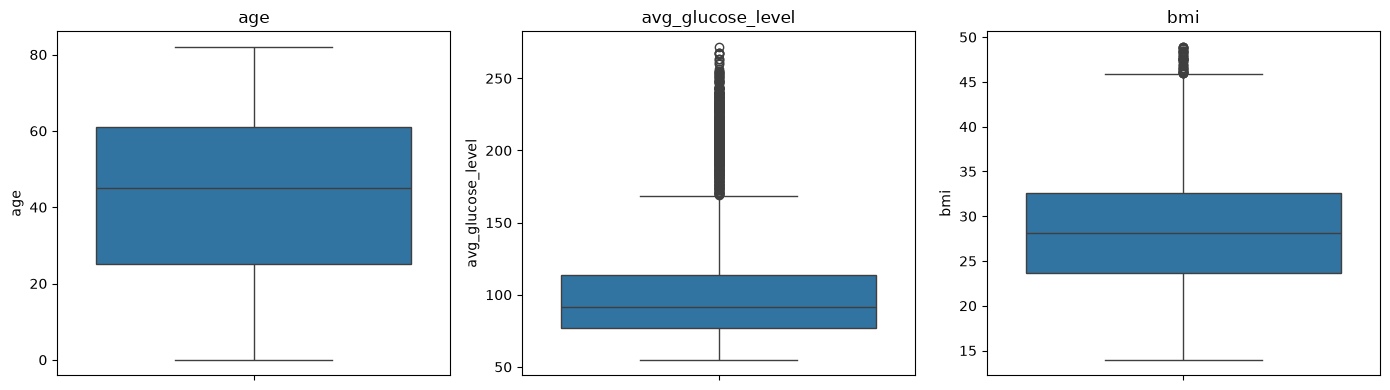

In [9]:
# 4.4 Check outliers with boxplots (XGBoost is robust to outliers, so we only look, we do not remove)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Step 5: Encoding techniques (demo on a copy first)
We will see 4 techniques, then use the best fit for each column in the final pipeline.

In [10]:
# Technique 1: Label Encoding (assigns 0,1,2... alphabetically). Good for binary columns / target.
demo = df.copy()
le = LabelEncoder()
demo["gender_label"] = le.fit_transform(demo["gender"])
print(dict(zip(le.classes_, le.transform(le.classes_))))
demo[["gender", "gender_label"]].head()

{'Female': 0, 'Male': 1}


,gender,gender_label
0,Male,1
1,Male,1
2,Female,0
3,Female,0
4,Male,1


In [11]:
# Technique 2: Ordinal Encoding with our own order. Good when categories have a natural order.
smoke_order = ["Unknown", "never smoked", "formerly smoked", "smokes"]
oe = OrdinalEncoder(categories=[smoke_order])
demo["smoking_ordinal"] = oe.fit_transform(demo[["smoking_status"]])
demo[["smoking_status", "smoking_ordinal"]].drop_duplicates()

,smoking_status,smoking_ordinal
0,formerly smoked,2.0
1,never smoked,1.0
2,smokes,3.0
7,Unknown,0.0


In [12]:
# Technique 3: One-Hot Encoding (one new 0/1 column per category). Good for nominal columns without order.
pd.get_dummies(demo["work_type"], prefix="work_type", drop_first=True).head()

,work_type_Private,work_type_Self-employed,work_type_children
0,True,False,False
1,True,False,False
2,True,False,False
3,False,True,False
4,True,False,False


In [13]:
# Technique 4: Frequency Encoding (replace category by how often it appears). Useful for high-cardinality columns.
freq = demo["work_type"].value_counts(normalize=True)
demo["work_type_freq"] = demo["work_type"].map(freq)
demo[["work_type", "work_type_freq"]].drop_duplicates()

,work_type,work_type_freq
0,Private,0.574182
3,Self-employed,0.161413
9,Govt_job,0.129291
205,children,0.135113


In [14]:
demo.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,gender_label,smoking_ordinal,work_type_freq
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1,1,2.0,0.574182
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1,1,1.0,0.574182
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1,0,3.0,0.574182
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1,0,1.0,0.161413
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1,1,2.0,0.574182


## Step 6: Split features and target, then Train-Test split
We split BEFORE encoding fit and SMOTE, so no information leaks from the test set.

In [15]:
X = df.drop("stroke", axis=1)
y = df["stroke"]

print("Class counts:")
print(y.value_counts())
print("\nStroke percentage: %.2f%%" % (y.mean() * 100))

Class counts:
stroke
0    4733
1     248
Name: count, dtype: int64

Stroke percentage: 4.98%


In [16]:
# stratify=y keeps the same class ratio in train and test
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(3984, 10) (997, 10) (3984,) (997,)


## Step 7: Build the preprocessing (encoding + scaling) with ColumnTransformer

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        # Label/Ordinal style encoding for binary columns
        ("binary", OrdinalEncoder(), ["gender", "ever_married", "Residence_type"]),
        # Ordinal encoding with custom order
        ("ordinal", OrdinalEncoder(categories=[smoke_order]), ["smoking_status"]),
        # One-hot encoding for nominal column
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), ["work_type"]),
        # Scaling numerical columns (not required for tree models, but it is a standard preprocessing step)
        ("scale", StandardScaler(), num_cols),
    ],
    remainder="passthrough"   # hypertension and heart_disease are kept as they are
)

# Fit only on train data, then transform both train and test
x_train_enc = preprocessor.fit_transform(x_train)
x_test_enc = preprocessor.transform(x_test)

print("Encoded train shape:", x_train_enc.shape)
print("Encoded test shape :", x_test_enc.shape)

Encoded train shape: (3984, 12)
Encoded test shape : (997, 12)


## Step 8: Handle imbalance with SMOTE (only on training data)

In [18]:
print("Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
x_train_sm, y_train_sm = smote.fit_resample(x_train_enc, y_train)

print("\nAfter SMOTE:")
print(y_train_sm.value_counts())

Before SMOTE:
stroke
0    3786
1     198
Name: count, dtype: int64

After SMOTE:
stroke
0    3786
1    3786
Name: count, dtype: int64


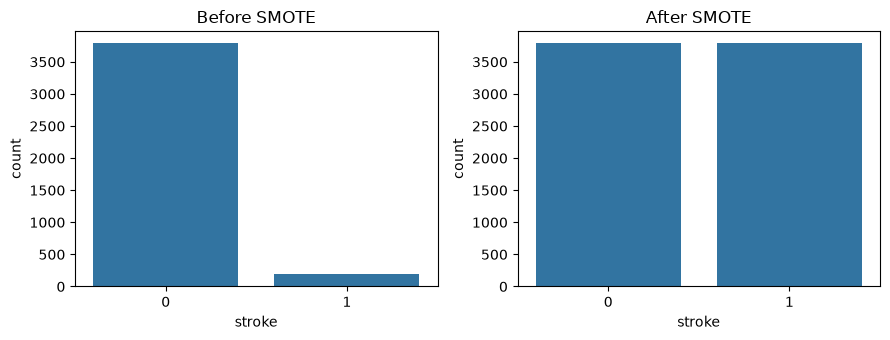

In [19]:
# Visual comparison of class counts before and after SMOTE
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
sns.countplot(x=y_train, ax=axes[0]); axes[0].set_title("Before SMOTE")
sns.countplot(x=y_train_sm, ax=axes[1]); axes[1].set_title("After SMOTE")
plt.tight_layout()
plt.show()

## Step 9: Baseline XGBoost models (without SMOTE vs with SMOTE)

In [20]:
# A small helper function to print all important metrics
def evaluate(model, X_te, y_te, name="Model"):
    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]
    print(f"===== {name} =====")
    print("Accuracy :", round(accuracy_score(y_te, y_pred), 4))
    print("Precision:", round(precision_score(y_te, y_pred), 4))
    print("Recall   :", round(recall_score(y_te, y_pred), 4))
    print("F1 score :", round(f1_score(y_te, y_pred), 4))
    print("ROC AUC  :", round(roc_auc_score(y_te, y_prob), 4))
    print("Confusion matrix:\n", confusion_matrix(y_te, y_pred))
    print()

In [21]:
# Model trained on original imbalanced data
xgb_plain = XGBClassifier(random_state=42, eval_metric="logloss")
xgb_plain.fit(x_train_enc, y_train)
evaluate(xgb_plain, x_test_enc, y_test, "XGBoost WITHOUT SMOTE")

===== XGBoost WITHOUT SMOTE =====
Accuracy : 0.9458
Precision: 0.1667
Recall   : 0.02
F1 score : 0.0357
ROC AUC  : 0.8098
Confusion matrix:
 [[942   5]
 [ 49   1]]



In [22]:
# Model trained on SMOTE balanced data
xgb_smote = XGBClassifier(random_state=42, eval_metric="logloss")
xgb_smote.fit(x_train_sm, y_train_sm)
evaluate(xgb_smote, x_test_enc, y_test, "XGBoost WITH SMOTE")

===== XGBoost WITH SMOTE =====
Accuracy : 0.9178
Precision: 0.119
Recall   : 0.1
F1 score : 0.1087
ROC AUC  : 0.7984
Confusion matrix:
 [[910  37]
 [ 45   5]]



In [23]:
# Detailed report of the SMOTE model
print(classification_report(y_test, xgb_smote.predict(x_test_enc)))

              precision    recall  f1-score   support

           0       0.95      0.96      0.96       947
           1       0.12      0.10      0.11        50

    accuracy                           0.92       997
   macro avg       0.54      0.53      0.53       997
weighted avg       0.91      0.92      0.91       997



## Step 10: Hyperparameter tuning with RandomizedSearchCV
We put preprocessing + SMOTE + XGBoost inside one imblearn Pipeline.
So inside every CV fold, SMOTE is applied only on the training part of that fold (no leakage).

In [26]:
pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(random_state=42, eval_metric="logloss")),
])

# Parameter names use the "xgb__" prefix because the model step is named "xgb"
param_dist = {
    "xgb__n_estimators": [100, 200, 300, 500],
    "xgb__max_depth": [3, 4, 5, 6, 8],
    "xgb__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "xgb__subsample": [0.6, 0.8, 1.0],
    "xgb__colsample_bytree": [0.6, 0.8, 1.0],
    "xgb__gamma": [0, 0.1, 0.3, 0.5],
    "xgb__min_child_weight": [1, 3, 5],
    "xgb__reg_alpha": [0, 0.1, 1],
    "xgb__reg_lambda": [1, 1.5, 2],
}

In [27]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=20,            # number of random combinations to try
    scoring="f1",         # F1 is better than accuracy for imbalanced data
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

# Fit on raw train data (pipeline does encoding + SMOTE + model by itself)
random_search.fit(x_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'xgb__colsample_bytree': [0.6, 0.8, ...], 'xgb__gamma': [0, 0.1, ...], 'xgb__learning_rate': [0.01, 0.05, ...], 'xgb__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, 

In [28]:
print("Best parameters:")
for k, v in random_search.best_params_.items():
    print(f"  {k}: {v}")
print("\nBest CV F1 score:", round(random_search.best_score_, 4))

Best parameters:
  xgb__subsample: 0.8
  xgb__reg_lambda: 1.5
  xgb__reg_alpha: 0.1
  xgb__n_estimators: 100
  xgb__min_child_weight: 3
  xgb__max_depth: 5
  xgb__learning_rate: 0.01
  xgb__gamma: 0
  xgb__colsample_bytree: 0.6

Best CV F1 score: 0.2402


## Step 11: Evaluate the tuned model on the test set

In [29]:
best_model = random_search.best_estimator_

# Pipeline takes raw x_test, applies preprocessing automatically (SMOTE is skipped at predict time)
evaluate(best_model, x_test, y_test, "Tuned XGBoost + SMOTE")
print(classification_report(y_test, best_model.predict(x_test)))

===== Tuned XGBoost + SMOTE =====
Accuracy : 0.8084
Precision: 0.1493
Recall   : 0.6
F1 score : 0.239
ROC AUC  : 0.8152
Confusion matrix:
 [[776 171]
 [ 20  30]]

              precision    recall  f1-score   support

           0       0.97      0.82      0.89       947
           1       0.15      0.60      0.24        50

    accuracy                           0.81       997
   macro avg       0.56      0.71      0.56       997
weighted avg       0.93      0.81      0.86       997



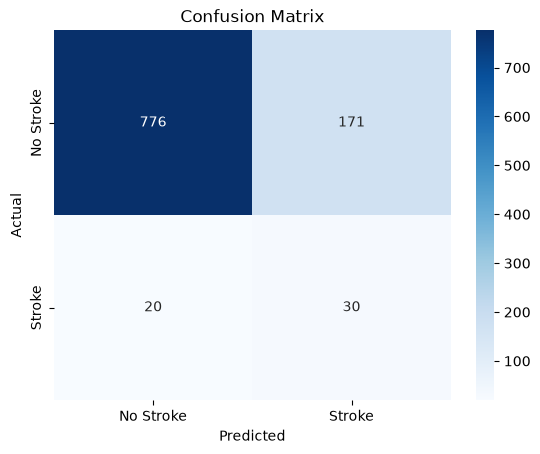

In [30]:
# Confusion matrix plot
cm = confusion_matrix(y_test, best_model.predict(x_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Stroke", "Stroke"], yticklabels=["No Stroke", "Stroke"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.show()

## Step 12: Cross Validation (Stratified K-Fold) on the full data
This gives a more reliable estimate than a single train-test split.

In [31]:
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results = cross_validate(
    best_model, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=scoring,
    n_jobs=-1,
)

for m in scoring:
    scores = cv_results[f"test_{m}"]
    print(f"{m:10s} -> mean: {scores.mean():.4f} | std: {scores.std():.4f} | folds: {np.round(scores, 3)}")

accuracy   -> mean: 0.8016 | std: 0.0116 | folds: [0.817 0.8   0.812 0.79  0.788]
precision  -> mean: 0.1507 | std: 0.0128 | folds: [0.167 0.15  0.159 0.149 0.128]
recall     -> mean: 0.6411 | std: 0.0400 | folds: [0.66  0.64  0.64  0.694 0.571]
f1         -> mean: 0.2439 | std: 0.0189 | folds: [0.266 0.243 0.255 0.245 0.21 ]
roc_auc    -> mean: 0.8144 | std: 0.0159 | folds: [0.817 0.816 0.807 0.84  0.791]


In [32]:
# Summary table of fold-wise scores
cv_df = pd.DataFrame({m: cv_results[f"test_{m}"] for m in scoring})
cv_df.index = [f"Fold {i}" for i in range(1, 6)]
cv_df.loc["Mean"] = cv_df.mean()
cv_df.round(4)

,accuracy,precision,recall,f1,roc_auc
Fold 1,0.8175,0.1667,0.6600,0.2661,0.8173
Fold 2,0.8002,0.1502,0.6400,0.2433,0.8161
Fold 3,0.8122,0.1592,0.6400,0.2550,0.8074
Fold 4,0.7902,0.1491,0.6939,0.2455,0.8402
Fold 5,0.7882,0.1284,0.5714,0.2097,0.7910
Mean,0.8016,0.1507,0.6411,0.2439,0.8144


## Step 13: Compare imbalance methods (Plain vs SMOTE vs scale_pos_weight) + Threshold tuning
Same XGBoost parameters for all, so only the imbalance method is different.
We use out-of-fold probabilities from cross validation, so every row is predicted by a model that did not see it.

In [33]:
from sklearn.model_selection import cross_val_predict

# Same base parameters for every variant (fair comparison)
base_params = dict(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                   colsample_bytree=0.8, min_child_weight=3, random_state=42, eval_metric="logloss")

# scale_pos_weight = (number of negatives) / (number of positives)
spw = (y == 0).sum() / (y == 1).sum()
print("scale_pos_weight:", round(spw, 2))

variants = {
    "Plain": Pipeline([("preprocess", preprocessor),
                       ("xgb", XGBClassifier(**base_params))]),
    "SMOTE": Pipeline([("preprocess", preprocessor),
                       ("smote", SMOTE(random_state=42)),
                       ("xgb", XGBClassifier(**base_params))]),
    "scale_pos_weight": Pipeline([("preprocess", preprocessor),
                                  ("xgb", XGBClassifier(scale_pos_weight=spw, **base_params))]),
}

scale_pos_weight: 19.08


In [34]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Out-of-fold predicted probabilities for every variant
oof_probs = {}
for name, model in variants.items():
    oof_probs[name] = cross_val_predict(model, X, y, cv=cv5, method="predict_proba")[:, 1]

# Metrics at the default threshold 0.5
rows = []
for name, prob in oof_probs.items():
    pred = (prob >= 0.5).astype(int)
    rows.append({
        "Method": name,
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "ROC AUC": roc_auc_score(y, prob),
    })
compare_df = pd.DataFrame(rows).set_index("Method").round(3)
compare_df

,Precision,Recall,F1,ROC AUC
Method,,,,
Plain,0.286,0.008,0.016,0.829
SMOTE,0.166,0.383,0.232,0.805
scale_pos_weight,0.139,0.690,0.231,0.822


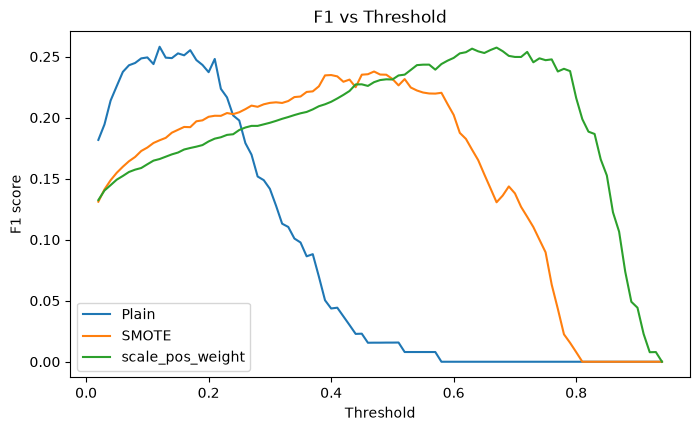

,Best threshold,Precision,Recall,F1
Method,,,,
Plain,0.12,0.176,0.484,0.258
SMOTE,0.47,0.164,0.431,0.238
scale_pos_weight,0.67,0.174,0.492,0.257


In [35]:
# Threshold tuning: instead of 0.5, find the threshold that gives the best F1
thresholds = np.arange(0.02, 0.95, 0.01)

plt.figure(figsize=(8, 4.5))
best_rows = []
for name, prob in oof_probs.items():
    f1s = [f1_score(y, (prob >= t).astype(int)) for t in thresholds]
    best_t = thresholds[int(np.argmax(f1s))]
    best_pred = (prob >= best_t).astype(int)
    best_rows.append({
        "Method": name,
        "Best threshold": round(best_t, 2),
        "Precision": precision_score(y, best_pred),
        "Recall": recall_score(y, best_pred),
        "F1": f1_score(y, best_pred),
    })
    plt.plot(thresholds, f1s, label=name)

plt.xlabel("Threshold"); plt.ylabel("F1 score"); plt.title("F1 vs Threshold")
plt.legend(); plt.show()

pd.DataFrame(best_rows).set_index("Method").round(3)

**How to read this:**
- SMOTE / scale_pos_weight mostly move the decision boundary, so recall goes up at threshold 0.5.
- ROC AUC shows the real ranking quality of the model. If it does not improve, the model did not really become better.
- Plain model + a lower threshold can give similar F1, so always try threshold tuning too.
- The best threshold is picked on the same data, so the F1 is slightly optimistic. For a strict estimate, choose the threshold on validation data and report on test data.

## Final notes
- Split first, then encode/scale/SMOTE only on train data to avoid data leakage.
- For imbalanced data, check Recall, F1 and ROC AUC, not only accuracy.
- SMOTE is used inside the Pipeline so it is applied correctly in every CV fold.
- SMOTE is not always better; compare with scale_pos_weight and threshold tuning (Step 13).